In [ ]:
!nvidia-smi

Wed Nov 11 09:25:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
%%writefile project.cu
#include <cstdio>
#include <vector>
#include <cmath>
#include <cstdlib>

// Camera parameters
const int W = 640;
const int H = 480;
const float fx = 500.0f, fy = 500.0f;    // focal length (zoom), in pixels
const float cx = 320.0f, cy = 240.0f;    // image center
const float R[3][3] = {{1, 0, 0},
                       {0, 1, 0},
                       {0, 0, 1}};
const float t[3] = {0, 0, 0};

struct Point {
  float x, y , z;
};

struct Camera {
  float R[3][3];
  float t[3];
  float fx, fy, cx, cy;
  int W, H;
};

__device__ void atomicMinFloat(float* addr, float val) {
  int* a = (int*)addr;
  int old = *a;
  while (val < __int_as_float(old)) {                        // is my value still smaller?
    int prev = atomicCAS(a, old, __float_as_int(val));       // try to swap it in
    if (prev == old) break;                                  // nobody changed it: I won
    old = prev;                                              // someone beat me: re-check and retry
  }
}


// Runs on the GPU. One thread = one dot. Same logic as your CPU loop body.
__global__ void depthKernel(const Point* pts, int N, Camera cam, float* depth) {
  int i = blockIdx.x * blockDim.x + threadIdx.x;   // which dot is mine?
  if (i >= N) return;                               // extra thread, no dot

  Point p = pts[i];
  float xc = cam.R[0][0]*p.x + cam.R[0][1]*p.y + cam.R[0][2]*p.z + cam.t[0];
  float yc = cam.R[1][0]*p.x + cam.R[1][1]*p.y + cam.R[1][2]*p.z + cam.t[1];
  float zc = cam.R[2][0]*p.x + cam.R[2][1]*p.y + cam.R[2][2]*p.z + cam.t[2];
  if (zc < 0.1f) return;                            // behind camera

  float u = cam.fx * (xc / zc) + cam.cx;
  float v = cam.fy * (yc / zc) + cam.cy;
  int px = (int)floorf(u);
  int py = (int)floorf(v);
  if (px < 0 || px >= cam.W || py < 0 || py >= cam.H) return;   // off the photo

  int idx = py * cam.W + px;
  atomicMinFloat(&depth[idx], zc);                 // closer? overwrite the note

}
float randFloat(float min, float max) {
  return min + (max - min) * ((float)rand() / RAND_MAX);
}

// CHANGED: added `float& z` so project also hands back the camera depth
bool project(Point p, float& u, float& v, float& z) {
  float xc = R[0][0]*p.x + R[0][1]*p.y + R[0][2]*p.z + t[0];
  float yc = R[1][0]*p.x + R[1][1]*p.y + R[1][2]*p.z + t[1];
  float zc = R[2][0]*p.x + R[2][1]*p.y + R[2][2]*p.z + t[2];
  if (zc < 0.1f) return false;
  u = fx * (xc / zc) + cx;
  v = fy * (yc / zc) + cy;
  z = zc;                                  // NEW: depth as seen from the camera
  return true;
}

int main() {
  const int N = 1000000;
  const float PI = 3.14159265f;
  std::vector<Point> pts(N);

  // ---- Scene settings ----
  const float floorY = 1.5f;
  const float radius = 2.0f;
  const Point center = {0.0f, floorY - radius, 8.0f};

  // ---- Generate points ----
  srand(0);
  for (int i = 0; i < N; i++) {
    if (i < N / 2) {
      pts[i].x = randFloat(-10, 10);
      pts[i].y = floorY;
      pts[i].z = randFloat(1, 30);
    }
    else {
      float h = randFloat(-1, 1);
      float theta = randFloat(0, 2 * PI);
      float s = sqrtf(1 - h * h);
      pts[i].x = s * cosf(theta) * radius + center.x;
      pts[i].y = h * radius + center.y;
      pts[i].z = s * sinf(theta) * radius + center.z;
    }
  }

  // ---- Check sphere ----
  float maxErr = 0.0f;
  for (int i = N / 2; i < N; i++) {
    float dx = pts[i].x - center.x;
    float dy = pts[i].y - center.y;
    float dz = pts[i].z - center.z;
    float dist = sqrtf(dx * dx + dy * dy + dz * dz);
    float err = fabsf(dist - radius);
    maxErr = fmaxf(maxErr, err);
  }
  printf("max sphere error: %e\n", maxErr);

  // ---- Save points for the 3D viewer ----
  FILE* f = fopen("points.txt", "w");
  for (int i = 0; i < N; i++) {
    fprintf(f, "%f %f %f\n", pts[i].x, pts[i].y, pts[i].z);
  }
  fclose(f);

  // ---- Save projected pixels for the scatter viewer ----
  FILE* img = fopen("pixels.txt", "w");
  int visible = 0;
  for (int i = 0; i < N; i++) {
    float u, v, z;                                   // CHANGED: added z
    if (project(pts[i], u, v, z)) {                  // CHANGED: pass z
      if (u >= 0 && u < W && v >= 0 && v < H) {
        fprintf(img, "%f %f %f\n", u, v, z);         // CHANGED: camera depth, not pts[i].z
        visible++;
      }
    }
  }
  fclose(img);
  printf("%d of %d dots are visible in the photo\n", visible, N);

  // ---- NEW: Depth buffer — one sticky note per pixel, keep the closest ----
  std::vector<float> depth(W * H, 1e30f);            // every pixel starts "really far"
  for (int i = 0; i < N; i++) {
    float u, v, z;
    if (!project(pts[i], u, v, z)) continue;         // behind camera → skip

    int px = (int)floorf(u);                         // which column box
    int py = (int)floorf(v);                         // which row box
    if (px < 0 || px >= W || py < 0 || py >= H) continue;   // off the photo → skip

    int idx = py * W + px;                           // box position in the long list
    if (z < depth[idx]) depth[idx] = z;              // closer? overwrite the note
  }

  // ---- NEW: Count how many boxes got something ----
  int filled = 0;
  for (int i = 0; i < W * H; i++) {
    if (depth[i] < 1e29f) filled++;
  }
  printf("%d of %d pixels have something in them\n", filled, W * H);

  // ---- NEW: Save depth as a grayscale image (near = white, far = dark, empty = black) ----
  const float dMin = 1.0f, dMax = 30.0f;
  std::vector<unsigned char> gray(W * H, 0);
  for (int i = 0; i < W * H; i++) {
    if (depth[i] < 1e29f) {
      float s = (depth[i] - dMin) / (dMax - dMin);   // where this distance sits in the range: 0 to 1
      s = fminf(fmaxf(s, 0.0f), 1.0f);               // anything outside the range gets pinned to 0 or 1
      gray[i] = 255 * (1 - s);                       // 0 → white (255), 1 → black (0)
    }
  }

  // ---- GPU depth buffer ----
  Camera cam = {{{1,0,0},{0,1,0},{0,0,1}}, {0,0,0}, fx, fy, cx, cy, W, H};

  Point* d_pts;      // "d_" = lives on the device (GPU)
  float* d_depth;
  cudaMalloc(&d_pts, N * sizeof(Point));               // like malloc, but on the GPU
  cudaMalloc(&d_depth, W * H * sizeof(float));

  std::vector<float> gpuDepth(W * H, 1e30f);           // starting values: "really far"
  cudaMemcpy(d_pts, pts.data(), N * sizeof(Point), cudaMemcpyHostToDevice);
  cudaMemcpy(d_depth, gpuDepth.data(), W * H * sizeof(float), cudaMemcpyHostToDevice);

  int threads = 256;
  int blocks = (N + threads - 1) / threads;            // enough blocks to cover all N dots
  depthKernel<<<blocks, threads>>>(d_pts, N, cam, d_depth);
  cudaDeviceSynchronize();                              // wait for all threads (like pthread_join)
  printf("kernel status: %s\n", cudaGetErrorString(cudaGetLastError()));

  cudaMemcpy(gpuDepth.data(), d_depth, W * H * sizeof(float), cudaMemcpyDeviceToHost);
  cudaFree(d_pts);
  cudaFree(d_depth);

  int mismatches = 0;
  for (int k = 0; k < W * H; k++) {
    if (gpuDepth[k] != depth[k]) mismatches++;
  }
  printf("GPU vs CPU: %d of %d pixels differ\n", mismatches, W * H);


  FILE* pg = fopen("depth.pgm", "wb");
  fprintf(pg, "P5\n%d %d\n255\n", W, H);
  fwrite(gray.data(), 1, W * H, pg);
  fclose(pg);
  printf("saved depth.pgm\n");

  return 0;


}

Overwriting project.cu


In [ ]:
!nvcc -O2 -arch=sm_75 -fmad=false project.cu -o project && ./project

max sphere error: 7.152557e-07
877090 of 1000000 dots are visible in the photo
102588 of 307200 pixels have something in them
kernel status: no error
GPU vs CPU: 0 of 307200 pixels differ
saved depth.pgm


In [ ]:
!g++ -O2 -x c++ project.cu -o project && ./project

project.cu:28:1: error: ‘__global__’ does not name a type
   28 | __global__ void depthKernel(const Point* pts, int N, Camera cam, float* depth) {
      | ^~~~~~~~~~
project.cu: In function ‘int main()’:
project.cu:162:3: error: ‘cudaMalloc’ was not declared in this scope; did you mean ‘calloc’?
  162 |   cudaMalloc(&d_pts, N * sizeof(Point));               // like malloc, but on the GPU
      |   ^~~~~~~~~~
      |   calloc
project.cu:166:52: error: ‘cudaMemcpyHostToDevice’ was not declared in this scope
  166 |   cudaMemcpy(d_pts, pts.data(), N * sizeof(Point), cudaMemcpyHostToDevice);
      |                                                    ^~~~~~~~~~~~~~~~~~~~~~
project.cu:166:3: error: ‘cudaMemcpy’ was not declared in this scope
  166 |   cudaMemcpy(d_pts, pts.data(), N * sizeof(Point), cudaMemcpyHostToDevice);
      |   ^~~~~~~~~~
project.cu:171:3: error: ‘depthKernel’ was not declared in this scope
  171 |   depthKernel<<<blocks, threads>>>(d_pts, N, cam, d_depth);
      |   ^

In [ ]:
%%writefile bench.cu
#include <cstdio>
#include <vector>
#include <cmath>
#include <cstdlib>
#include <chrono>
#include <algorithm>

// Stop with a clear message if any CUDA call fails (CUDA errors are silent otherwise)
#define CHECK(call) do { cudaError_t e = (call); if (e != cudaSuccess) { \
  printf("CUDA error: %s (line %d)\n", cudaGetErrorString(e), __LINE__); exit(1); } } while (0)

const int W = 640, H = 480;
const float fx = 500.0f, fy = 500.0f, cx = 320.0f, cy = 240.0f;

struct Point { float x, y, z; };
struct Camera { float R[3][3]; float t[3]; float fx, fy, cx, cy; int W, H; };

float randFloat(float a, float b) { return a + (b - a) * ((float)rand() / RAND_MAX); }

// Same scene as project.cu: half floor, half ball resting on it
void makeScene(std::vector<Point>& pts) {
  const int N = pts.size();
  const float PI = 3.14159265f, floorY = 1.5f, radius = 2.0f;
  const Point center = {0.0f, floorY - radius, 8.0f};
  srand(0);
  for (int i = 0; i < N; i++) {
    if (i < N / 2) {
      pts[i].x = randFloat(-10, 10);
      pts[i].y = floorY;
      pts[i].z = randFloat(1, 30);
    } else {
      float h = randFloat(-1, 1), theta = randFloat(0, 2 * PI), s = sqrtf(1 - h * h);
      pts[i].x = s * cosf(theta) * radius + center.x;
      pts[i].y = h * radius + center.y;
      pts[i].z = s * sinf(theta) * radius + center.z;
    }
  }
}

// CPU reference: one worker, one dot at a time
void cpuDepth(const std::vector<Point>& pts, const Camera& cam, std::vector<float>& depth) {
  std::fill(depth.begin(), depth.end(), 1e30f);
  for (size_t i = 0; i < pts.size(); i++) {
    const Point& p = pts[i];
    float xc = cam.R[0][0]*p.x + cam.R[0][1]*p.y + cam.R[0][2]*p.z + cam.t[0];
    float yc = cam.R[1][0]*p.x + cam.R[1][1]*p.y + cam.R[1][2]*p.z + cam.t[1];
    float zc = cam.R[2][0]*p.x + cam.R[2][1]*p.y + cam.R[2][2]*p.z + cam.t[2];
    if (zc < 0.1f) continue;
    int px = (int)floorf(cam.fx * (xc / zc) + cam.cx);
    int py = (int)floorf(cam.fy * (yc / zc) + cam.cy);
    if (px < 0 || px >= cam.W || py < 0 || py >= cam.H) continue;
    int idx = py * cam.W + px;
    if (zc < depth[idx]) depth[idx] = zc;
  }
}

// GPU version: one thread per dot, atomicMin fixes the race
__global__ void depthKernel(const Point* pts, int N, Camera cam, float* depth) {
  int i = blockIdx.x * blockDim.x + threadIdx.x;
  if (i >= N) return;
  Point p = pts[i];
  float xc = cam.R[0][0]*p.x + cam.R[0][1]*p.y + cam.R[0][2]*p.z + cam.t[0];
  float yc = cam.R[1][0]*p.x + cam.R[1][1]*p.y + cam.R[1][2]*p.z + cam.t[1];
  float zc = cam.R[2][0]*p.x + cam.R[2][1]*p.y + cam.R[2][2]*p.z + cam.t[2];
  if (zc < 0.1f) return;
  int px = (int)floorf(cam.fx * (xc / zc) + cam.cx);
  int py = (int)floorf(cam.fy * (yc / zc) + cam.cy);
  if (px < 0 || px >= cam.W || py < 0 || py >= cam.H) return;
  atomicMin((int*)&depth[py * cam.W + px], __float_as_int(zc));
}

int main() {
  Camera cam = {{{1,0,0},{0,1,0},{0,0,1}}, {0,0,0}, fx, fy, cx, cy, W, H};
  CHECK(cudaSetDeviceFlags(cudaDeviceMapHost));   // allow the GPU to read mapped CPU memory
  CHECK(cudaFree(0));   // wake up the GPU now, so startup cost isn't counted in any timing

  int sizes[3] = {100000, 1000000, 10000000};
  printf("%10s %10s %11s %11s %14s %6s %6s\n",
       "N", "CPU ms", "kernel ms", "pinned ms", "zero-copy ms", "diff", "zdiff");

  for (int s = 0; s < 3; s++) {
    int N = sizes[s];
    std::vector<Point> pts(N);
    makeScene(pts);
    std::vector<float> cpu(W * H), gpu(W * H, 1e30f);

    // ---- CPU timing ----
    auto t0 = std::chrono::high_resolution_clock::now();
    cpuDepth(pts, cam, cpu);
    auto t1 = std::chrono::high_resolution_clock::now();
    double cpuMs = std::chrono::duration<double, std::milli>(t1 - t0).count();

    // ---- GPU setup (not timed) ----
    Point* d_pts; float* d_depth;
    CHECK(cudaMalloc(&d_pts, N * sizeof(Point)));
    CHECK(cudaMalloc(&d_depth, W * H * sizeof(float)));
    int threads = 256, blocks = (N + threads - 1) / threads;
    Point* h_pts;                                         // pinned CPU buffer
    CHECK(cudaMallocHost(&h_pts, N * sizeof(Point)));     // allocate locked memory
    std::copy(pts.begin(), pts.end(), h_pts);             // copy points into it

    // Warm-up run (not timed): the first launch of a kernel is slower
    CHECK(cudaMemcpy(d_pts, pts.data(), N * sizeof(Point), cudaMemcpyHostToDevice));
    CHECK(cudaMemcpy(d_depth, gpu.data(), W * H * sizeof(float), cudaMemcpyHostToDevice));
    depthKernel<<<blocks, threads>>>(d_pts, N, cam, d_depth);
    CHECK(cudaDeviceSynchronize());

    // ---- GPU timing: copies in, kernel, copy out ----
    cudaEvent_t e0, e1, e2, e3;
    cudaEventCreate(&e0); cudaEventCreate(&e1); cudaEventCreate(&e2); cudaEventCreate(&e3);

    CHECK(cudaEventRecord(e0));                               // start: before copying in
    CHECK(cudaMemcpy(d_pts, h_pts, N * sizeof(Point), cudaMemcpyHostToDevice));
    CHECK(cudaMemcpy(d_depth, gpu.data(), W * H * sizeof(float), cudaMemcpyHostToDevice));
    CHECK(cudaEventRecord(e1));                               // kernel starts
    depthKernel<<<blocks, threads>>>(d_pts, N, cam, d_depth);
    CHECK(cudaGetLastError());
    CHECK(cudaEventRecord(e2));                               // kernel ends
    CHECK(cudaMemcpy(gpu.data(), d_depth, W * H * sizeof(float), cudaMemcpyDeviceToHost));
    CHECK(cudaEventRecord(e3));                               // end: after copying out
    CHECK(cudaEventSynchronize(e3));

    float kernelMs, totalMs;
    cudaEventElapsedTime(&kernelMs, e1, e2);
    cudaEventElapsedTime(&totalMs, e0, e3);

    // ---- Zero-copy: kernel reads points straight from CPU RAM over PCIe ----
    Point* h_mapped;                                           // CPU-side pointer
    Point* d_mapped;                                           // GPU-side pointer to the SAME memory
    CHECK(cudaHostAlloc(&h_mapped, N * sizeof(Point), cudaHostAllocMapped));
    std::copy(pts.begin(), pts.end(), h_mapped);
    CHECK(cudaHostGetDevicePointer(&d_mapped, h_mapped, 0));
    std::vector<float> zeroDepth(W * H, 1e30f);

    // Warm-up (not timed)
    CHECK(cudaMemcpy(d_depth, zeroDepth.data(), W * H * sizeof(float), cudaMemcpyHostToDevice));
    depthKernel<<<blocks, threads>>>(d_mapped, N, cam, d_depth);
    CHECK(cudaDeviceSynchronize());

    // Timed run: NO cudaMemcpy for the points
    cudaEvent_t z0, z1;
    cudaEventCreate(&z0); cudaEventCreate(&z1);
    CHECK(cudaEventRecord(z0));
    CHECK(cudaMemcpy(d_depth, zeroDepth.data(), W * H * sizeof(float), cudaMemcpyHostToDevice));
    depthKernel<<<blocks, threads>>>(d_mapped, N, cam, d_depth);   // reads points over PCIe
    CHECK(cudaGetLastError());
    CHECK(cudaMemcpy(zeroDepth.data(), d_depth, W * H * sizeof(float), cudaMemcpyDeviceToHost));
    CHECK(cudaEventRecord(z1));
    CHECK(cudaEventSynchronize(z1));

    float zeroMs;
    cudaEventElapsedTime(&zeroMs, z0, z1);

    int zdiff = 0;
    for (int k = 0; k < W * H; k++) if (zeroDepth[k] != cpu[k]) zdiff++;

    // ---- Correctness: GPU must match CPU exactly ----
    int diff = 0;
    for (int k = 0; k < W * H; k++) if (gpu[k] != cpu[k]) diff++;

    printf("%10d %10.2f %11.3f %11.2f %14.2f %6d %6d\n",
       N, cpuMs, kernelMs, totalMs, zeroMs, diff, zdiff);

    cudaEventDestroy(e0); cudaEventDestroy(e1); cudaEventDestroy(e2); cudaEventDestroy(e3);
    cudaEventDestroy(z0); cudaEventDestroy(z1);
    cudaFreeHost(h_mapped);
    cudaFree(d_pts); cudaFree(d_depth); cudaFreeHost(h_pts);
  }
  return 0;
}

Overwriting bench.cu


In [ ]:
!nvcc -O2 -arch=sm_75 -fmad=false bench.cu -o bench && ./bench

         N     CPU ms   kernel ms   pinned ms   zero-copy ms   diff  zdiff
    100000       2.61       0.023        0.77           0.71      0      0
   1000000      24.96       0.087        1.66           1.59      0      0
  10000000     200.12       1.077       11.37          10.30      0      0


In [ ]:
import numpy as np
import plotly.graph_objects as go

pts = np.loadtxt("points.txt")
idx = np.random.choice(len(pts), 30000, replace=False)
p = pts[idx]

fig = go.Figure(go.Scatter3d(
    x=p[:, 0], y=p[:, 2], z=-p[:, 1],
    mode="markers",
    marker=dict(size=1.5, color=p[:, 2], colorscale="Viridis"),
))
fig.update_layout(scene=dict(aspectmode="data",
                             xaxis_title="x (right)",
                             yaxis_title="z (forward)",
                             zaxis_title="up"))
fig.show()

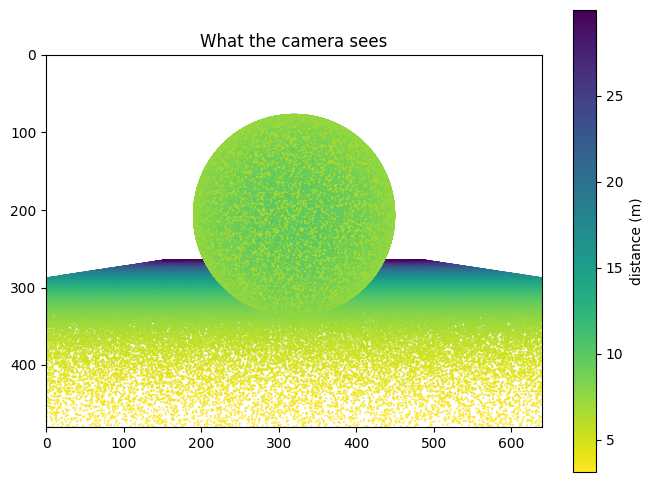

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

d = np.loadtxt("pixels.txt")
plt.figure(figsize=(8, 6))
plt.scatter(d[:, 0], d[:, 1], c=d[:, 2], s=0.2, cmap="viridis_r")
plt.xlim(0, 640)
plt.ylim(480, 0)          # flip so row 0 is at the TOP, like a real image
plt.gca().set_aspect("equal")
plt.colorbar(label="distance (m)")
plt.title("What the camera sees")
plt.show()

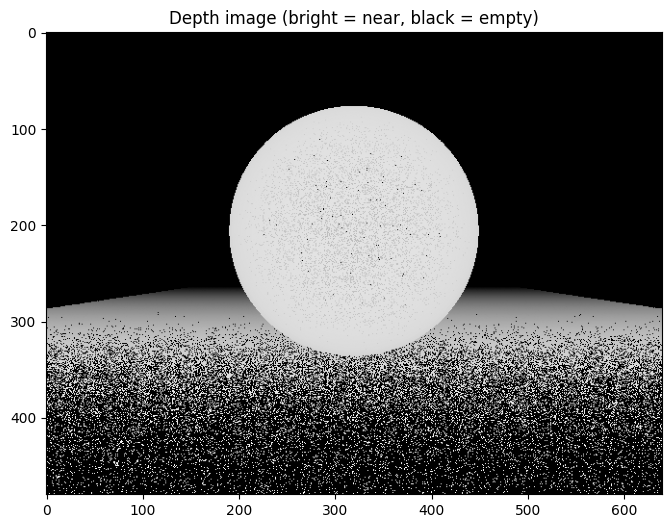

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open("depth.pgm")
plt.figure(figsize=(8, 6))
plt.imshow(img, cmap="gray")
plt.title("Depth image (bright = near, black = empty)")
plt.show()